In [28]:
from fastai.imports import *

In [29]:
#uploading the Data
from google.colab import files
uploaded = files.upload()

In [30]:
#unzip files
data_path = Path("titanic.zip")
with zipfile.ZipFile(data_path, 'r') as zip_f:
    zip_f.extractall()

In [31]:
df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [32]:
# we make the iloc[0] becasue the  make its work on the 1st dim by default so we make the dim [864,12]--->[1,12] so we get the first row --> iloc[0]
modes = df.mode().iloc[0]

In [33]:
def process_data (df):
  df['Fare'] = df['Fare'].fillna(0) #we are making NAN filled with 0 because this is not a NN (coeff*0 makes a problem) so it is better to make it 0
  df.fillna(modes,inplace=True) #inplace=True means modify the original DataFrame directly instead of returning a new one
  df['LogFare'] = np.log1p(df['Fare']) # log1p ==> log(__+1)
  df['Embarked'] = pd.Categorical(df['Embarked'])
  df['Sex'] = pd.Categorical(df['Sex'])


process_data(df)
process_data(test_df)

In [34]:
cats=["Sex","Embarked"]
conts=['Age', 'SibSp', 'Parch', 'LogFare',"Pclass"]
dep="Survived"

In [35]:
df['Sex'].head()#Even although we've made the cats columns categorical, they are still shown by Pandas as their original values:

,Sex
0,male
1,female
2,female
3,female
4,male


In [36]:
df.Sex.cat.codes.head() # use this funciton to show the stored numerics that pandas made

,0
0,1
1,0
2,0
3,0
4,1


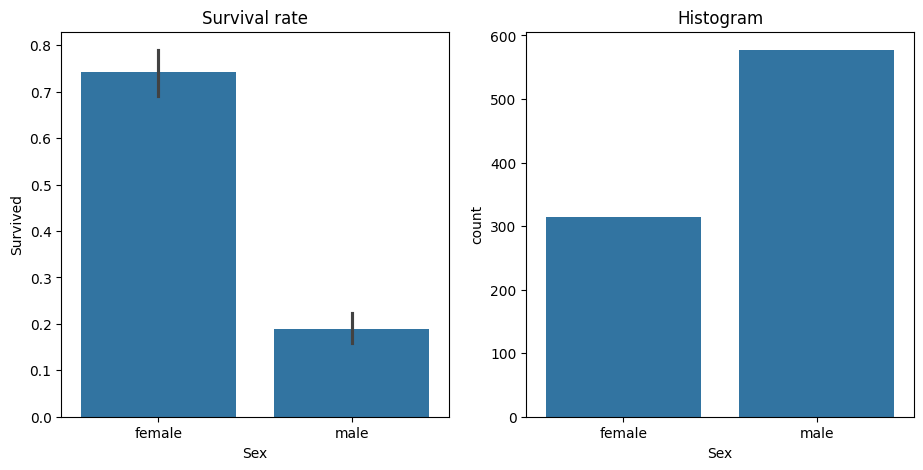

In [37]:
#make a visualizaiton
import seaborn as sns

fig,axs = plt.subplots(1,2, figsize=(11,5))
sns.barplot(data=df, y=dep, x="Sex", ax=axs[0]).set(title="Survival rate")  # ax=__  --> is the plot that we draw on
sns.countplot(data=df, x="Sex", ax=axs[1]).set(title="Histogram");

In [38]:
# lets make the splits
from numpy import random
from sklearn.model_selection import train_test_split
trn_df,val_df = train_test_split(df, test_size=0.25)
trn_df[cats] = trn_df[cats].apply(lambda x: x.cat.codes)# lambda is just a shortcut for making {def__fn__(): return...what is after lambda...} , and it is used when we are applying this stuff to more than one column /// and for the cat.code --> it is just to replace the strings or whatever by the numeric values that pandas made
val_df[cats] = val_df[cats].apply(lambda x: x.cat.codes)

In [39]:
# lets make a funciton that makes us the indep variables (xs), and the dep variables (y)
def xs_y(df,cats=cats,conts=conts,dep=dep):
  xs = df[cats+conts].copy() # make a copy so that we dont change the main df
  return xs ,df[dep] if dep in df else None
trn_xs,trn_y = xs_y(trn_df)
val_xs,val_y = xs_y(val_df)

In [40]:
#lets make the simple tree preds --> female lives (female-->0)
preds = val_xs.Sex==0

In [41]:
#calc the error
from sklearn.metrics import mean_absolute_error
mean_absolute_error(val_y, preds)

0.21076233183856502

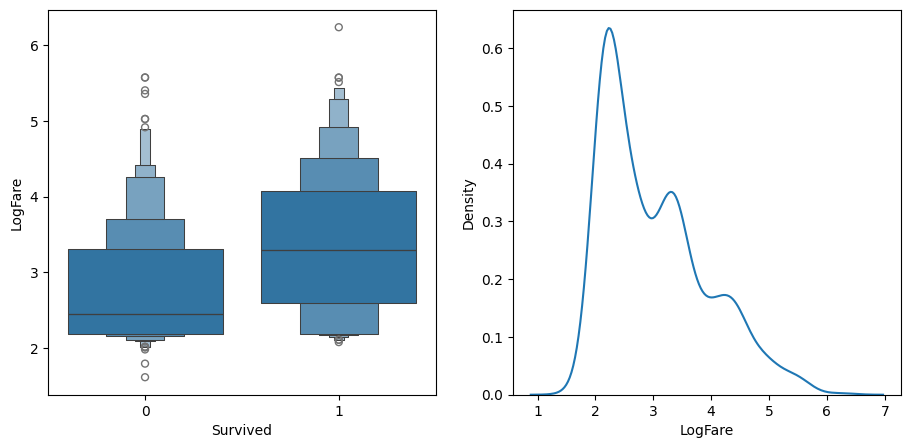

In [42]:
df_fare = trn_df [trn_df.LogFare>0] # we make this to make us remove the rows that have 0 Fare because those are the ones that we have added and they are not accurate
fig,axs = plt.subplots(1,2, figsize=(11,5))
sns.boxenplot(data=df_fare, x=dep, y="LogFare", ax=axs[0])
sns.kdeplot(data=df_fare, x="LogFare", ax=axs[1]);

In [43]:
# we can see that most of the people that had Fare>2.6 made it  , lets make model
preds = val_xs.LogFare>2.7

In [44]:
mean_absolute_error(val_y, preds)


0.34080717488789236

In [45]:
# we are going to make a funciton that -> (see how much is the side that was made after answering the question similar by using the  standard deviation (std) --> Range[0(best pure),0.5(worst)] ):
def side_score (side, # eg.-->[True,True,False,True]
                y): # it is the survive row
  total = side.sum() # --> count how many of the rows there from the split(question that made the split) so the [True] there means that this is a column that is included in the split and false means that it is not included
  if total<=1: return 0 # becasue if the total was [F] or [T,F] , etc --> this means that there is one row so that cant be more pure  /// and the return stops the funciton
  return y[side].std()*total  # 1) here we are seeing the survive or not based on the side that we made using y[T,F,..] --> give [1,...] and then we make the std , 2) we make the *tot --> for scale , big and bad(worst and big effect) , small and bad (worst and small effect)


In [46]:
# now we can make function that sees how good a split is:
def score (col ,y,split):
  lhs = col<=split
  return (side_score(lhs,y) + side_score(~lhs,y))/len(y) # (~) just make negation so that we get the other side

In [47]:
# impurity of sex -- (lower = better)
score(trn_xs["Sex"] , trn_y , 0.5).round(5)

np.float64(0.40999)

In [48]:
#now logfare
score(trn_xs["LogFare"], trn_y, 2.7).round(5)

np.float64(0.47567)

In [49]:
# now we can make it look for the best split value
nm="Age"
col = trn_xs[nm]
unique = col.unique()
unique.sort()
unique

array([ 0.42,  0.67,  0.75,  0.83,  0.92,  1.  ,  2.  ,  3.  ,  4.  ,
        5.  ,  6.  ,  7.  ,  8.  ,  9.  , 10.  , 11.  , 13.  , 14.  ,
       14.5 , 15.  , 16.  , 17.  , 18.  , 19.  , 20.  , 20.5 , 21.  ,
       22.  , 23.  , 24.  , 25.  , 26.  , 27.  , 28.  , 28.5 , 29.  ,
       30.  , 30.5 , 31.  , 32.  , 32.5 , 33.  , 34.  , 34.5 , 35.  ,
       36.  , 36.5 , 37.  , 38.  , 39.  , 40.  , 40.5 , 41.  , 42.  ,
       43.  , 44.  , 45.  , 45.5 , 46.  , 47.  , 48.  , 49.  , 50.  ,
       51.  , 52.  , 53.  , 54.  , 55.  , 55.5 , 56.  , 57.  , 58.  ,
       59.  , 60.  , 61.  , 62.  , 63.  , 64.  , 65.  , 70.  , 70.5 ,
       71.  ])

In [50]:
scores = np.array([score(col,trn_y,o) for o in unique if not np.isnan(o)]) # here at the end we check if it is nan , and it is not going to make a problem with indexing because the sort we made pushes nan ti the end , dropna() even removes the nan of you want
unique[scores.argmin()] #the argmin() gets us the index

np.float64(0.92)

In [51]:
# now we can make a function that makes this
def min_col(df, nm):
    col,y = df[nm],df[dep]
    unq = col.dropna().unique() # this even removes the nan
    scores = np.array([score(col, y, o) for o in unq if not np.isnan(o)])
    idx = scores.argmin()
    return unq[idx].item(),scores[idx].round(7).item()

min_col(trn_df, "Age")

(0.92, 0.4843413)

In [52]:
#lets make it for all columns
cols = cats+conts
{o : min_col(trn_df,o) for o in cols}

{'Sex': (0, 0.4099873),
 'Embarked': (0, 0.4876372),
 'Age': (0.92, 0.4843413),
 'SibSp': (4, 0.4837686),
 'Parch': (0, 0.4859138),
 'LogFare': (2.4390808375825834, 0.4672092),
 'Pclass': (2, 0.4600208)}

## now lets make the same but for the female and male

In [53]:
# remove the sex column for the cols
cols.remove("Sex")
ismale = trn_df.Sex==1
males,females = trn_df[ismale] , trn_df[~ismale]

In [55]:
#lets see
{o:min_col(males,o) for o in cols}

{'Embarked': (0, 0.3978418),
 'Age': (9.0, 0.3836665),
 'SibSp': (4, 0.3949865),
 'Parch': (0, 0.3939477),
 'LogFare': (2.775447133088262, 0.3870155),
 'Pclass': (1, 0.386454)}

In [56]:
{o:min_col(females,o) for o in cols}

{'Embarked': (1, 0.4260204),
 'Age': (50.0, 0.416385),
 'SibSp': (2, 0.4112088),
 'Parch': (1, 0.4147181),
 'LogFare': (3.8691155044168695, 0.3982509),
 'Pclass': (2, 0.3338122)}

In [59]:
# so we can see how that work lets make it using sktlearn
from sklearn.tree import DecisionTreeClassifier, export_graphviz
tree = DecisionTreeClassifier(max_leaf_nodes=4).fit(trn_xs,trn_y) #we make the 4 nodes to prevent OverFitting

In [60]:
import graphviz

def draw_tree(t, df, size=10, ratio=0.6, precision=2, **kwargs):
    s=export_graphviz(t,
                      out_file=None,
                      feature_names=df.columns,
                      filled=True,
                      rounded=True,
                      special_characters=True,
                      rotate=False,
                      precision=precision,
                      **kwargs)
    return graphviz.Source(re.sub('Tree {', f'Tree {{ size={size}; ratio={ratio}', s))

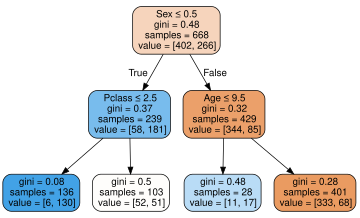

In [62]:
draw_tree(tree, trn_xs, size=5)

In [68]:
#gini is something that is like the std
def gini (condition ):# list of T and F that tells us what are the rows to include
  survival_list = df.loc[condition,dep] # --> [1,1,0,0,1,....]
  return (1 - survival_list.mean()**2 - (1-survival_list).mean()**2).round(6).item()

In [69]:
#lets use it , lower better as std
gini(df.Sex=='female') , gini(df.Sex=='male')

(0.382835, 0.306444)

In [70]:
# lets use the sklearn to see model MAE
mean_absolute_error(val_y , tree.predict(val_xs))

0.21524663677130046

In [71]:
cats

['Sex', 'Embarked']

In [74]:
# lets make the kaggle preds for the test
#first process the Data
process_data(test_df)
test_df[cats] = test_df[cats].apply(lambda x : x.cat.codes)
test_xs,_ = xs_y(test_df) # _ because we dont need it
def submit (preds , path_name):
  test_df['Survived'] = preds
  sb_df = test_df[['PassengerId' , 'Survived']]
  sb_df.to_csv(f"{path_name}.csv", index=False)

submit(tree.predict(test_xs) , "tree_submission")

In [75]:
df.Embarked.head()

,Embarked
0,S
1,C
2,S
3,S
4,S


# *making random forests (voting dicision trees)*

In [81]:
# making a fuction that DT with random Data splits
def get_tree (ratio=0.75):
  n = len(trn_xs)
  random_indicies = random.choice(n , #range to choose from
                                  int(n*ratio)) # no elements to choose
  return DecisionTreeClassifier(min_samples_leaf=5# that is to prevent overfitting and the model memorizing the Data
                                ).fit(trn_xs.iloc[random_indicies],trn_y.iloc[random_indicies]) # we use the iloc because this is not boolean


In [82]:
trees = [get_tree() for i in range(100)]

In [90]:
all_preds = [tree.predict(val_xs) for tree in trees]
#to see the shape make it to np array
all_preds = np.array(all_preds)
all_preds.shape

(100, 223)

In [91]:
# now take avg
avg_preds = all_preds.mean(0) # we make 0 becasue the default just gives one number
mean_absolute_error(val_y , avg_preds)

0.22

In [92]:
# now we can see the sklearn version the thing that makes it better is that it takes random subsets of the columns so some trees cant see Sex , etc....
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(100, min_samples_leaf=5)
rf.fit(trn_xs, trn_y);
mean_absolute_error(val_y, rf.predict(val_xs))

0.18385650224215247

In [95]:
submit(rf.predict(test_xs),'random_forest submision')

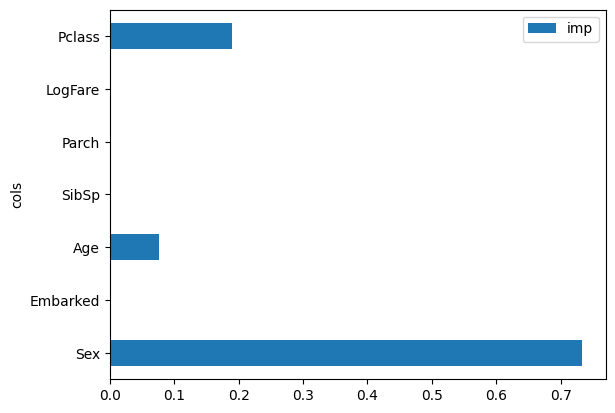

In [96]:
# lets visualize
pd.DataFrame(dict(cols=trn_xs.columns, imp=tree.feature_importances_)).plot('cols', 'imp', 'barh');